# Módulo IV – Aprendizado de Máquina
## Aula 2: classificação e regressão
**Profa. Kadidja Valéria | UDF | Sistemas de Informação | 2026.2**

Objetivos: preparar dados, separar treino/teste, treinar árvore de decisão e regressão linear, avaliar e interpretar erros. Todos os registros deste laboratório são **sintéticos**, sem dados de estudantes reais. Relações foram definidas por uma simulação e não constituem evidência sobre evasão.

No Colab: Arquivo > Fazer upload de notebook, selecione este `.ipynb` e execute as células na ordem. Em Jupyter, use Python 3. Se faltarem bibliotecas: execute `%pip install numpy pandas matplotlib scikit-learn`. O código usa APIs públicas consultadas em 14/10/2026 e informa as versões efetivamente executadas.

In [1]:
import sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.linear_model import LinearRegression
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.metrics import (accuracy_score, confusion_matrix, ConfusionMatrixDisplay,
                             mean_absolute_error, r2_score)
SEMENTE = 42
print('Python:', sys.version.split()[0])
print('NumPy:', np.__version__, 'pandas:', pd.__version__,
      'matplotlib:', plt.matplotlib.__version__, 'scikit-learn:', sklearn.__version__)

Python: 3.13.16
NumPy: 2.5.3 pandas: 3.0.5 matplotlib: 3.11.2 scikit-learn: 1.9.1


## 1. Dados e pergunta de negócio
Quem poderia receber um convite voluntário de apoio antes do fim do semestre? Unidade de análise: um estudante fictício. Atributos: frequência, nota e entregas observadas **até a semana 4**. Alvo: `evasao_fim_semestre` (0 = permaneceu, 1 = evadiu). Em um estudo real, definir evasão, janela temporal e critérios de inclusão antes da coleta. Identificadores não entram no modelo.

A simulação abaixo define uma probabilidade e sorteia o desfecho. O ruído impede que a classe seja uma certeza. Ausências são introduzidas para ensinar imputação (substituição de valores ausentes).

In [2]:
rng = np.random.default_rng(SEMENTE)
n = 600
frequencia = rng.uniform(35, 100, n)
nota = rng.uniform(0, 10, n)
entregas = rng.integers(0, 9, n)
logit = -0.4 + (65 - frequencia)/18 + (5 - nota)/2 + (4 - entregas)/3
prob_simulada = 1 / (1 + np.exp(-logit))
alvo = rng.binomial(1, prob_simulada)
dados = pd.DataFrame({'frequencia_sem4': frequencia,
                      'nota_sem4': nota, 'entregas_sem4': entregas,
                      'evasao_fim_semestre': alvo})
dados.loc[rng.choice(n, 30, replace=False), 'nota_sem4'] = np.nan
# Arquivo com dados brutos. O Orange fará a avaliação em seu próprio fluxo.
dados.to_csv('dados_educacionais_sinteticos.csv', index=False)
print(dados.head().to_string(index=False))
print('Dimensões:', dados.shape)
print('Ausentes por coluna:\n', dados.isna().sum())
print('Classes (%):\n', dados['evasao_fim_semestre'].value_counts(normalize=True).mul(100).round(1))

 frequencia_sem4  nota_sem4  entregas_sem4  evasao_fim_semestre
       85.307143   4.775059              0                    1
       63.527099   7.614326              5                    1
       90.808865   9.033279              6                    0
       80.328922   7.206959              4                    0
       41.121528   9.632112              3                    1
Dimensões: (600, 4)
Ausentes por coluna:
 frequencia_sem4         0
nota_sem4              30
entregas_sem4           0
evasao_fim_semestre     0
dtype: int64
Classes (%):
 evasao_fim_semestre
0    59.0
1    41.0
Name: proportion, dtype: float64


## 2. Separação antes de aprender transformações
`X` reúne atributos, `y` contém o alvo. Reservamos 25% dos registros para teste. `stratify=y` mantém aproximadamente a proporção das classes. A divisão aleatória é apropriada para este exercício com observações independentes. Para prever novas turmas, reservar períodos futuros. Se houver vários registros do mesmo estudante, separar por estudante.

A exploração detalhada e a escolha dos parâmetros usam apenas o treino. O teste fica reservado para a avaliação final.

Treino: 450 Teste: 150
       frequencia_sem4  nota_sem4  entregas_sem4
count           450.00     427.00         450.00
mean             67.19       5.13           4.10
std              18.66       2.91           2.65
min              35.48       0.01           0.00
25%              50.54       2.55           2.00
50%              67.27       5.15           4.00
75%              83.53       7.73           7.00
max              99.94       9.99           8.00


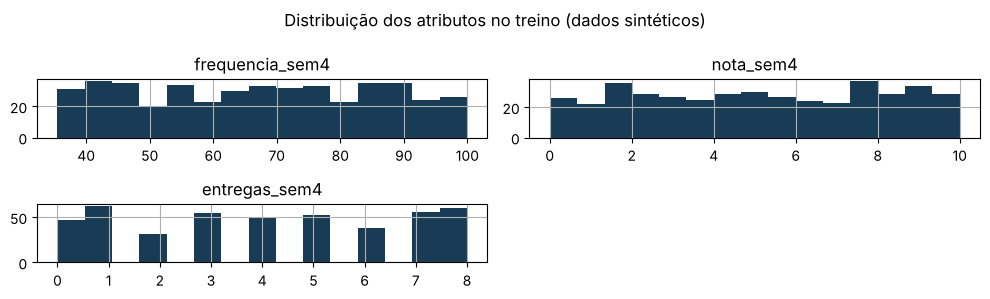

In [3]:
atributos = ['frequencia_sem4', 'nota_sem4', 'entregas_sem4']
X = dados[atributos]
y = dados['evasao_fim_semestre']
X_treino, X_teste, y_treino, y_teste = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=SEMENTE)
print('Treino:', len(X_treino), 'Teste:', len(X_teste))
print(X_treino.describe().round(2))
X_treino.hist(figsize=(10, 3), bins=15, color='#183b56')
plt.suptitle('Distribuição dos atributos no treino (dados sintéticos)')
plt.tight_layout(); plt.show()

## 3. Preparação e escolha da árvore no treino
A mediana de cada coluna é aprendida dentro do `Pipeline`, que encadeia preparação e modelo. Isso impede usar informação do teste ao imputar. Árvore de decisão aprende perguntas sobre os atributos. `max_depth` limita níveis e `min_samples_leaf` limita folhas muito pequenas. Árvores não precisam de padronização neste exemplo.

Comparamos profundidades com validação cruzada estratificada em cinco partes do treino. Cada parte serve como validação uma vez. **O teste não participa da escolha.** A diferença treino/validação ajuda a investigar sobreajuste. O maior valor médio não garante superioridade em outra população.

In [4]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMENTE)
comparacao = []
for profundidade in [2, 3, 5, None]:
    candidato = Pipeline([
        ('imputador', SimpleImputer(strategy='median')),
        ('arvore', DecisionTreeClassifier(max_depth=profundidade,
                    min_samples_leaf=10, random_state=SEMENTE))])
    scores = cross_validate(candidato, X_treino, y_treino, cv=cv,
                            scoring='accuracy', return_train_score=True)
    comparacao.append({'profundidade': str(profundidade),
                      'acuracia_treino_cv': scores['train_score'].mean(),
                      'acuracia_validacao_cv': scores['test_score'].mean(),
                      'desvio_validacao_cv': scores['test_score'].std()})
comparacao = pd.DataFrame(comparacao)
print(comparacao.round(4).to_string(index=False))
melhor = comparacao.sort_values('acuracia_validacao_cv', ascending=False,
                               kind='stable').iloc[0]
prof = None if melhor['profundidade'] == 'None' else int(melhor['profundidade'])
modelo = Pipeline([
    ('imputador', SimpleImputer(strategy='median')),
    ('arvore', DecisionTreeClassifier(max_depth=prof, min_samples_leaf=10,
                                    random_state=SEMENTE))])
modelo.fit(X_treino, y_treino)
print('Profundidade escolhida somente no treino:', prof)

profundidade  acuracia_treino_cv  acuracia_validacao_cv  desvio_validacao_cv
           2              0.7328                 0.6844               0.0425
           3              0.7678                 0.7022               0.0257
           5              0.8111                 0.7222               0.0391
        None              0.8206                 0.7111               0.0477
Profundidade escolhida somente no treino: 5


## 4. Avaliação final em dados não vistos
Acurácia = acertos / total. Matriz: linhas são classes reais, colunas são previstas. Para classe positiva 1, `[0,0]` = verdadeiro negativo, `[0,1]` = falso positivo, `[1,0]` = falso negativo, `[1,1]` = verdadeiro positivo. Falso negativo pode deixar alguém sem convite de apoio, falso positivo pode gerar contato desnecessário. A ação deve ser voluntária e revisada por pessoas.

A referência `DummyClassifier` prevê a classe mais frequente do treino. Um modelo precisa justificar sua utilidade em relação a essa referência e aos custos dos erros.

Acurácia treino: 0.8133
Acurácia teste: 0.7800; referência: 0.5933
Matriz [linhas reais, colunas previstas]:
 [[75 14]
 [19 42]]
TN: 75 FP: 14 FN: 19 TP: 42
Sensibilidade classe 1: 0.6885245901639344


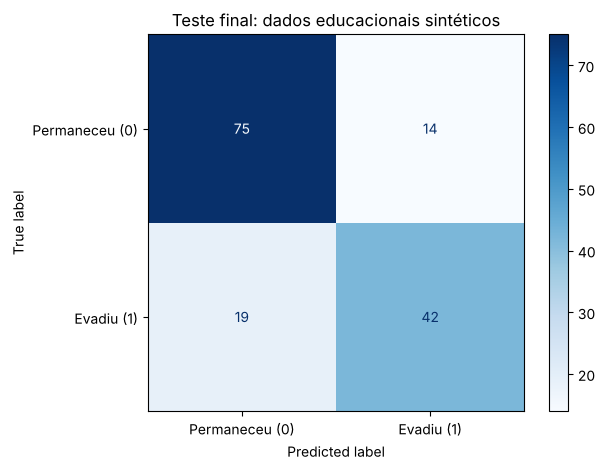

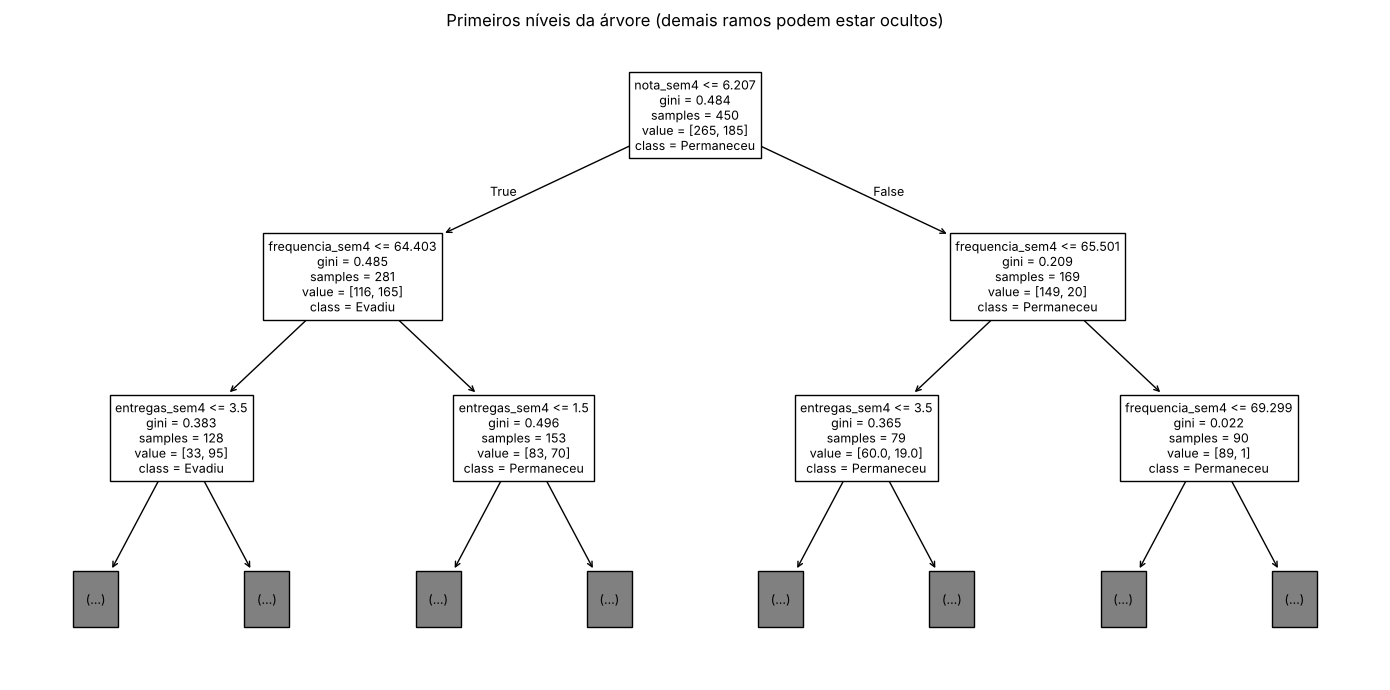

In [5]:
prev = modelo.predict(X_teste)
base = DummyClassifier(strategy='most_frequent').fit(X_treino, y_treino)
acc = accuracy_score(y_teste, prev)
acc_base = accuracy_score(y_teste, base.predict(X_teste))
cm = confusion_matrix(y_teste, prev, labels=[0, 1])
tn, fp, fn, tp = cm.ravel()
print(f'Acurácia treino: {modelo.score(X_treino, y_treino):.4f}')
print(f'Acurácia teste: {acc:.4f}; referência: {acc_base:.4f}')
print('Matriz [linhas reais, colunas previstas]:\n', cm)
print('TN:', tn, 'FP:', fp, 'FN:', fn, 'TP:', tp)
print('Sensibilidade classe 1:', tp/(tp+fn) if tp+fn else np.nan)
ConfusionMatrixDisplay(cm, display_labels=['Permaneceu (0)', 'Evadiu (1)']).plot(cmap='Blues')
plt.title('Teste final: dados educacionais sintéticos'); plt.tight_layout(); plt.show()
plt.figure(figsize=(14, 7))
plot_tree(modelo.named_steps['arvore'], feature_names=atributos,
          class_names=['Permaneceu', 'Evadiu'], max_depth=2, filled=False, fontsize=9)
plt.title('Primeiros níveis da árvore (demais ramos podem estar ocultos)')
plt.tight_layout(); plt.show()

## 5. Previsão de um novo registro fictício
A estimativa da árvore representa frequências nas folhas. Não é uma probabilidade garantida ou necessariamente calibrada. Um valor alto só pode orientar investigação e apoio. Importância de atributo e associação não demonstram causalidade.

In [6]:
novo = pd.DataFrame({'frequencia_sem4': [72.0], 'nota_sem4': [6.0],
                     'entregas_sem4': [5]})
indice_1 = list(modelo.named_steps['arvore'].classes_).index(1)
print('Classe prevista:', modelo.predict(novo)[0])
print('Estimativa para classe 1:', modelo.predict_proba(novo)[0, indice_1])

Classe prevista: 0
Estimativa para classe 1: 0.34210526315789475


## 6. Exercícios de investigação
1. Antes de olhar o teste, inclua `min_samples_leaf` = 5, 20 e 40 na comparação por validação cruzada. Explique a escolha. Para repetir a investigação após conhecer o teste, reserve um novo teste independente.
2. Registre médias e dispersões, não apenas o melhor número. Qual diferença entre ajuste no treino e generalização?
3. Calcule manualmente a acurácia a partir da matriz. Compare falso negativo e falso positivo.
4. Remova um atributo e avalie no treino por validação cruzada. A mudança prova que ele causa evasão? Justifique.
5. Se 95% permanecessem, qual seria a acurácia de sempre prever permanência? O que a matriz revelaria?
6. Proponha auditoria por grupos, acesso restrito, prazo de retenção e contestação. Este conjunto não contém grupos reais e não permite afirmar equidade.

**Limites:** a função que criou os dados escolheu as associações, há ruído e apenas uma divisão final. Dados sintéticos não validam uso institucional. Modelos reais requerem avaliação temporal, amostras representativas, participação dos estudantes e revisão ética.

# Seção independente: regressão linear
## 7. Estimativa de demanda de uma biblioteca
Alvo numérico: empréstimos por semana, aqui modelados como uma quantidade contínua para fins didáticos. Atributos fictícios: usuários ativos e horas de abertura. Regressão linear ajusta uma combinação dos atributos minimizando erros quadráticos. Não prova efeito causal das horas sobre empréstimos.

A divisão é aleatória porque a simulação gera registros independentes. Dados de semanas reais exigiriam preservar a ordem temporal e lidar com sazonalidade.

MAE teste: 28.59 empréstimos/semana
R² teste: 0.8774; MAE referência: 84.73
Coeficientes: [0.34798726 2.29702637]


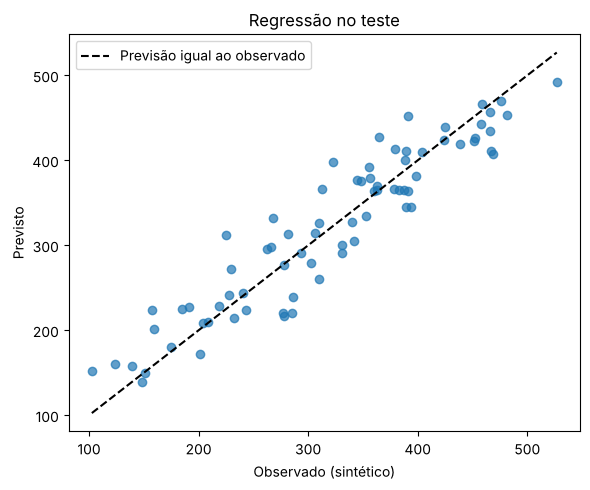

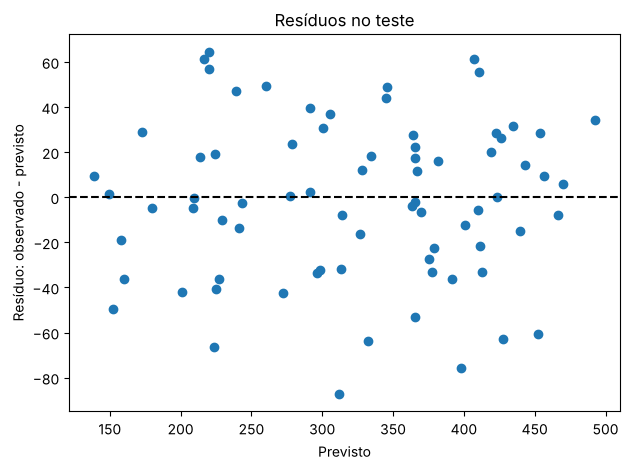

Nova previsão: 303.1919494072177


In [7]:
rng_reg = np.random.default_rng(SEMENTE)
reg = pd.DataFrame({'usuarios_ativos': rng_reg.uniform(100, 1000, 300),
                    'horas_abertura': rng_reg.uniform(20, 60, 300)})
reg['emprestimos_semana'] = (30 + 0.35*reg['usuarios_ativos'] +
                           2.5*reg['horas_abertura'] + rng_reg.normal(0, 35, 300))
Xr = reg[['usuarios_ativos', 'horas_abertura']]
yr = reg['emprestimos_semana']
Xr_tr, Xr_te, yr_tr, yr_te = train_test_split(Xr, yr, test_size=0.25,
                                            random_state=SEMENTE)
regressor = Pipeline([('imputador', SimpleImputer(strategy='median')),
                      ('linear', LinearRegression())])
regressor.fit(Xr_tr, yr_tr)
pr = regressor.predict(Xr_te)
ref_reg = DummyRegressor(strategy='mean').fit(Xr_tr, yr_tr)
mae = mean_absolute_error(yr_te, pr)
r2 = r2_score(yr_te, pr)
mae_base = mean_absolute_error(yr_te, ref_reg.predict(Xr_te))
print(f'MAE teste: {mae:.2f} empréstimos/semana')
print(f'R² teste: {r2:.4f}; MAE referência: {mae_base:.2f}')
print('Coeficientes:', regressor.named_steps['linear'].coef_)
plt.figure(figsize=(6, 5)); plt.scatter(yr_te, pr, marker='o', alpha=0.7)
lim = [min(yr_te.min(), pr.min()), max(yr_te.max(), pr.max())]
plt.plot(lim, lim, 'k--', label='Previsão igual ao observado')
plt.xlabel('Observado (sintético)'); plt.ylabel('Previsto')
plt.title('Regressão no teste'); plt.legend(); plt.tight_layout(); plt.show()
residuos = yr_te - pr
plt.scatter(pr, residuos); plt.axhline(0, color='black', linestyle='--')
plt.xlabel('Previsto'); plt.ylabel('Resíduo: observado - previsto')
plt.title('Resíduos no teste'); plt.tight_layout(); plt.show()
print('Nova previsão:', regressor.predict(pd.DataFrame(
    {'usuarios_ativos': [500], 'horas_abertura': [40]}))[0])

## 8. Interpretação da regressão
MAE é o erro absoluto médio, na mesma unidade do alvo. Menor é melhor, considerando a necessidade da biblioteca. R² compara a soma dos erros quadráticos com prever a média dos alvos **do conjunto avaliado**. Pode ser negativo, 1 indica ajuste perfeito, 0 equivale a essa referência. R² não é porcentagem de acertos. A referência treinada `DummyRegressor` usa a média do treino, portanto sua avaliação no teste não precisa dar exatamente R² = 0.

Exercícios: calcule os erros absolutos dos cinco primeiros registros, retire um atributo e compare por validação no treino, investigue os resíduos. Discuta extrapolação: prever para 10.000 usuários ultrapassa o domínio simulado. Não use os coeficientes como efeitos causais.

In [8]:
print(pd.DataFrame({'real': yr_te, 'previsto': pr,
                    'erro_absoluto': np.abs(yr_te-pr)}).head().round(2))
# Registro dos resultados realmente calculados nesta execução.
resultados = {'acuracia_treino': float(modelo.score(X_treino, y_treino)),
              'acuracia_teste': float(acc), 'acuracia_referencia': float(acc_base),
              'matriz_confusao': cm.tolist(), 'profundidade': prof,
              'mae': float(mae), 'r2': float(r2), 'mae_referencia': float(mae_base),
              'sklearn': sklearn.__version__, 'pandas': pd.__version__,
              'numpy': np.__version__, 'matplotlib': plt.matplotlib.__version__}
with open('resultados_execucao.json', 'w', encoding='utf-8') as f:
    json.dump(resultados, f, ensure_ascii=False, indent=2)

       real  previsto  erro_absoluto
203  208.90    209.40           0.50
266  277.71    277.32           0.39
152  190.95    227.18          36.23
9    229.67    271.95          42.29
233  359.77    363.62           3.85


## Referências e checklist
SCIKIT-LEARN. *User Guide*. Disponível em: https://scikit-learn.org/stable/user_guide.html. Acesso em: 14 out. 2026.
PANDAS. *User Guide*. Disponível em: https://pandas.pydata.org/docs/user_guide/index.html. Acesso em: 14 out. 2026.
MATPLOTLIB. *Pyplot tutorial*. Disponível em: https://matplotlib.org/stable/tutorials/pyplot.html. Acesso em: 14 out. 2026.

- [ ] Executei todas as células e registrei versões.
- [ ] Identifiquei atributos, alvo e janela temporal.
- [ ] Escolhi parâmetros apenas com o treino.
- [ ] Interpretei matriz, acurácia, MAE e R².
- [ ] Comparei referências e expliquei limitações.
- [ ] Propus apoio humano e proteção dos dados.